# Лабиринт и программируемая мышка
Выполняйте ячейки сверху вниз. Координаты — `(x, y)`. Grid — открытая закольцованная сетка; ClosedMaze устанавливает стены на её рёбра. Объекты живут в агрегатах Place и отображаются через реестр SVG-рендереров.

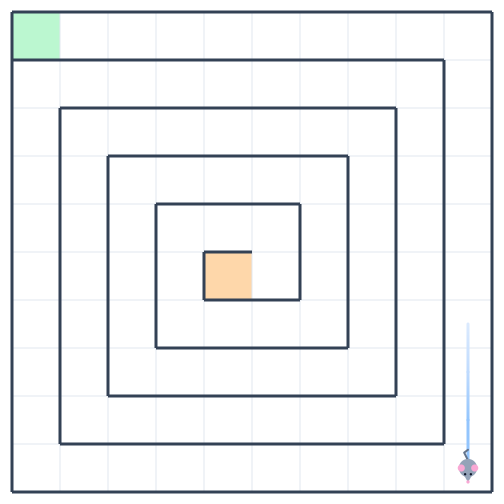

In [2]:
from IPython.display import display
from labyrinth import Direction, Grid, Mouse, PlaceObject, SpiralMaze
from labyrinth_view import MazeView

def create_demo():
    w = 10
    h = 10
    maze = SpiralMaze(w, h)
    mouse = Mouse(maze)
    return maze, mouse, MazeView(maze, mouse)

maze, mouse, view = create_demo()
view

In [3]:
from random import randint
from time import sleep

In [22]:
mouse.down()

1

In [13]:
mouse.right()

1

In [5]:
methods = (mouse.down, mouse.right, mouse.left, mouse.up)
for i in range(100):
    method = methods[randint(0, 3)]
    method()
    sleep(0.05)

In [ ]:
mouse.down()

In [ ]:
mouse.right(2)
mouse.down()
print('Клетка:', mouse.position, 'Выход:', mouse.at_exit)

In [ ]:
mouse.reset()
route = [next(d for d in Direction if d.delta == (b[0] - a[0], b[1] - a[1]))
         for a, b in zip(maze.spiral_path, maze.spiral_path[1:])]
await mouse.walk(route, delay=0.25)
print('Выход найден:', mouse.at_exit)

## Своя сетка: объекты между клетками
Grid не знает стен. Проход закрывается любым объектом с blocks_movement=True. Противоположные стороны соседних клеток возвращают один Place.

In [ ]:
my_grid = Grid(6, 4, entrance=(0, 0), exit=(5, 3))
barriers = []
for y in range(my_grid.height - 1):
    barrier = PlaceObject(blocks_movement=True)
    barriers.append(barrier)
    my_grid.place_between((1, y), 'right', barrier)
my_mouse = Mouse(my_grid)
my_view = MazeView(my_grid, my_mouse)
display(my_view)

In [ ]:
my_mouse.right(5)

In [ ]:
my_grid.remove_between((1, 0), 'right', barriers[0])
my_grid.entrance = (0, 1)
my_grid.exit = (5, 0)
my_mouse.reset()
my_view.show_trail = False
my_view.show_grid = False
print('Слева от корня закрыто:', my_grid.root.left.closed)
print('Соседи:', my_grid.neighbors(my_mouse.position))
print('Проходы:', my_grid.links)